*Importing Necessary Libraries*

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score

warnings.filterwarnings('ignore') # for ignoring warnings to keep the notebook clean (relevant issues are handled in later sections)

*Loading Dataset*

In [2]:
# read in csv file as a DataFrame
df= pd.read_csv('crime_dataset_india.csv')
df



,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed
0,1,02-01-2020 00:00,01-01-2020 00:00,01-01-2020 01:11,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,NaN
1,2,01-01-2020 19:00,01-01-2020 01:00,01-01-2020 06:26,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,NaN
2,3,02-01-2020 05:00,01-01-2020 02:00,01-01-2020 14:30,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,NaN
3,4,01-01-2020 05:00,01-01-2020 03:00,01-01-2020 14:46,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00
4,5,01-01-2020 21:00,01-01-2020 04:00,01-01-2020 16:51,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,08-01-2020 21:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40155,40156,01-08-2024 16:00,07-31-2024 03:00,31-07-2024 05:05,Kolkata,312,COUNTERFEITING,78,F,Firearm,Other Crime,12,No,NaN
40156,40157,31-07-2024 14:00,07-31-2024 04:00,31-07-2024 04:14,Mumbai,300,ILLEGAL POSSESSION,75,F,NaN,Other Crime,2,Yes,29-09-2024 14:00
40157,40158,02-08-2024 03:00,07-31-2024 05:00,31-07-2024 21:33,Kanpur,423,VEHICLE - STOLEN,68,M,Other,Violent Crime,6,No,NaN
40158,40159,01-08-2024 19:00,07-31-2024 06:00,31-07-2024 11:05,Patna,311,SEXUAL ASSAULT,11,M,Blunt Object,Violent Crime,1,No,NaN


*Data Preprocessing*

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40160 entries, 0 to 40159
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Report Number       40160 non-null  int64 
 1   Date Reported       40160 non-null  object
 2   Date of Occurrence  40160 non-null  object
 3   Time of Occurrence  40160 non-null  object
 4   City                40160 non-null  object
 5   Crime Code          40160 non-null  int64 
 6   Crime Description   40160 non-null  object
 7   Victim Age          40160 non-null  int64 
 8   Victim Gender       40160 non-null  object
 9   Weapon Used         34370 non-null  object
 10  Crime Domain        40160 non-null  object
 11  Police Deployed     40160 non-null  int64 
 12  Case Closed         40160 non-null  object
 13  Date Case Closed    20062 non-null  object
dtypes: int64(4), object(10)
memory usage: 4.3+ MB


In [4]:
df.describe()

,Report Number,Crime Code,Victim Age,Police Deployed
count,40160.000000,40160.000000,40160.00000,40160.000000
mean,20080.500000,349.360259,44.49126,10.006250
std,11593.337742,144.169205,20.22555,5.467951
min,1.000000,100.000000,10.00000,1.000000
25%,10040.750000,225.000000,27.00000,5.000000
50%,20080.500000,349.000000,44.00000,10.000000
75%,30120.250000,474.000000,62.00000,15.000000
max,40160.000000,599.000000,79.00000,19.000000


In [5]:
df.shape

(40160, 14)

*Checking Duplicate Values*

In [6]:
df.duplicated().sum()

0

In [8]:
df.columns

Index(['Report Number', 'Date Reported', 'Date of Occurrence',
       'Time of Occurrence', 'City', 'Crime Code', 'Crime Description',
       'Victim Age', 'Victim Gender', 'Weapon Used', 'Crime Domain',
       'Police Deployed', 'Case Closed', 'Date Case Closed'],
      dtype='object')

In [24]:
df.nunique()

Report Number         40160
Date Reported         25546
Date of Occurrence    40160
Time of Occurrence    39886
City                     29
Crime Code              500
Crime Description        21
Victim Age               70
Victim Gender             3
Weapon Used               6
Crime Domain              4
Police Deployed          19
Case Closed               2
Date Case Closed      16011
dtype: int64

*Checking For Null Values*

In [9]:
df.isnull().sum()

Report Number             0
Date Reported             0
Date of Occurrence        0
Time of Occurrence        0
City                      0
Crime Code                0
Crime Description         0
Victim Age                0
Victim Gender             0
Weapon Used            5790
Crime Domain              0
Police Deployed           0
Case Closed               0
Date Case Closed      20098
dtype: int64

*Treating Missing Values*

In [10]:
df['Weapon Used'] = df['Weapon Used'].fillna(df['Weapon Used'].mode()[0])
print(df['Weapon Used'])

0        Blunt Object
1              Poison
2        Blunt Object
3             Firearm
4               Other
             ...     
40155         Firearm
40156           Knife
40157           Other
40158    Blunt Object
40159          Poison
Name: Weapon Used, Length: 40160, dtype: object


In [11]:
df['Date Case Closed'] = df['Date Case Closed'].fillna(df['Date Case Closed'].mode()[0])
print(df['Date Case Closed'])

0        04-05-2024 18:00
1        04-05-2024 18:00
2        04-05-2024 18:00
3        29-04-2020 05:00
4        08-01-2020 21:00
               ...       
40155    04-05-2024 18:00
40156    29-09-2024 14:00
40157    04-05-2024 18:00
40158    04-05-2024 18:00
40159    28-09-2024 17:00
Name: Date Case Closed, Length: 40160, dtype: object


In [12]:
df.head()

,Report Number,Date Reported,Date of Occurrence,Time of Occurrence,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain,Police Deployed,Case Closed,Date Case Closed
0,1,02-01-2020 00:00,01-01-2020 00:00,01-01-2020 01:11,Ahmedabad,576,IDENTITY THEFT,16,M,Blunt Object,Violent Crime,13,No,04-05-2024 18:00
1,2,01-01-2020 19:00,01-01-2020 01:00,01-01-2020 06:26,Chennai,128,HOMICIDE,37,M,Poison,Other Crime,9,No,04-05-2024 18:00
2,3,02-01-2020 05:00,01-01-2020 02:00,01-01-2020 14:30,Ludhiana,271,KIDNAPPING,48,F,Blunt Object,Other Crime,15,No,04-05-2024 18:00
3,4,01-01-2020 05:00,01-01-2020 03:00,01-01-2020 14:46,Pune,170,BURGLARY,49,F,Firearm,Other Crime,1,Yes,29-04-2020 05:00
4,5,01-01-2020 21:00,01-01-2020 04:00,01-01-2020 16:51,Pune,421,VANDALISM,30,F,Other,Other Crime,18,Yes,08-01-2020 21:00


**EDA**

*Distribution of Victim Age by Gender*

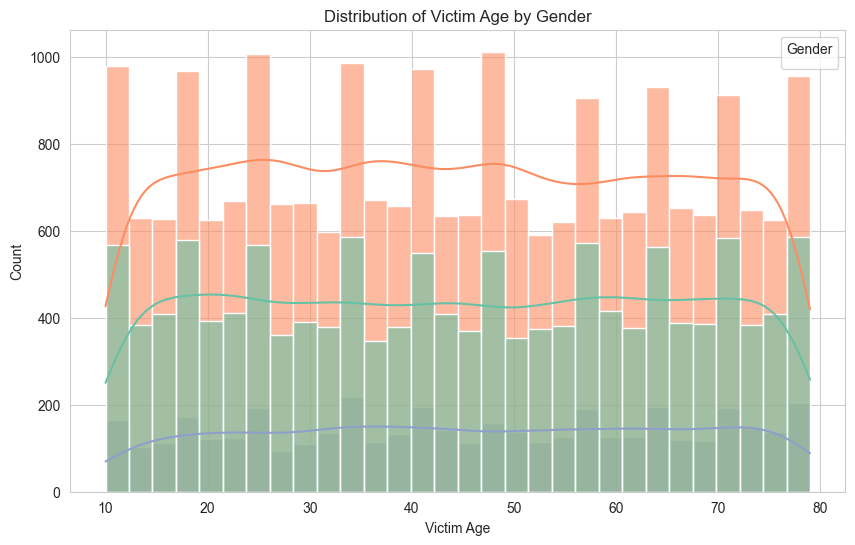

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_style("whitegrid")

# Plot distribution of victim age grouped by gender
plt.figure(figsize=(10, 6))
sns.histplot(df, x="Victim Age", hue="Victim Gender", bins=30, kde=True, palette="Set2", alpha=0.6)

# Labels and title
plt.xlabel("Victim Age")
plt.ylabel("Count")
plt.title("Distribution of Victim Age by Gender")
plt.legend(title="Gender")

# Show plot
plt.show()


*crime distribution by time of day*

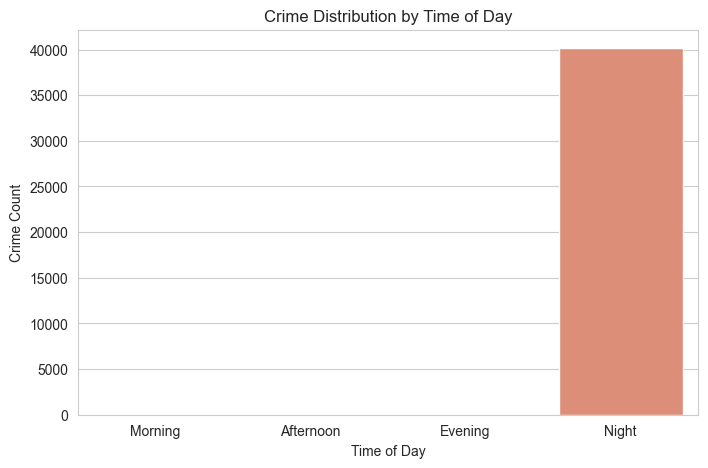

In [17]:
# Convert 'Time of Occurrence' to datetime format and extract hour
df["Time of Occurrence"] = pd.to_datetime(df["Time of Occurrence"], errors="coerce").dt.hour

# Define time of day categories
def categorize_time(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

# Apply categorization
df["Time of Day"] = df["Time of Occurrence"].apply(categorize_time)

# Plot crime distribution by time of day
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Time of Day", order=["Morning", "Afternoon", "Evening", "Night"], palette="coolwarm")

# Labels and title
plt.xlabel("Time of Day")
plt.ylabel("Crime Count")
plt.title("Crime Distribution by Time of Day")

# Show plot
plt.show()


*Top 10 Cities with Highest Crime Count*

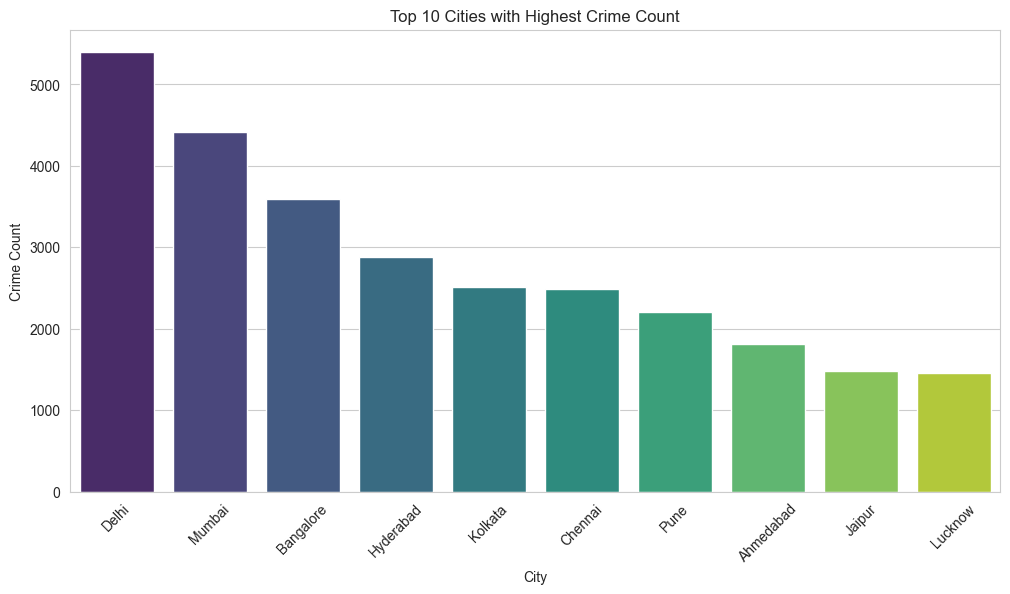

In [18]:
# Plot crime distribution by city (Top 10 cities with most crimes)
top_cities = df["City"].value_counts().nlargest(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_cities.index, y=top_cities.values, palette="viridis")

# Labels and title
plt.xlabel("City")
plt.ylabel("Crime Count")
plt.title("Top 10 Cities with Highest Crime Count")
plt.xticks(rotation=45)

# Show plot
plt.show()


*Mapping crime hotspots using City*

In [19]:
import pandas as pd
import folium
from folium.plugins import HeatMap

# Load dataset
file_path = "crime_dataset_india.csv"  # Update with the correct path
df = pd.read_csv(file_path)

# Sample city-to-coordinates mapping (Replace with actual latitude/longitude if available)
city_coords = {
    "Delhi": [28.6139, 77.2090],
    "Mumbai": [19.0760, 72.8777],
    "Bangalore": [12.9716, 77.5946],
    "Kolkata": [22.5726, 88.3639],
    "Chennai": [13.0827, 80.2707],
}

# Filter dataset to keep only cities in our mapping
df_filtered = df[df["City"].isin(city_coords.keys())]

# Group by city and get crime count
crime_counts = df_filtered["City"].value_counts()

# Convert crime counts to standard Python int
heat_data = [[city_coords[city][0], city_coords[city][1], int(crime_counts[city])] for city in crime_counts.index]

# Create a folium map centered in India
m = folium.Map(location=[20.5937, 78.9629], zoom_start=5)

# Add heatmap layer
HeatMap(heat_data).add_to(m)

# Save the map and display
m.save("crime_hotspots_map.html")
m


*Top 10 Crime Domains by Frequency*

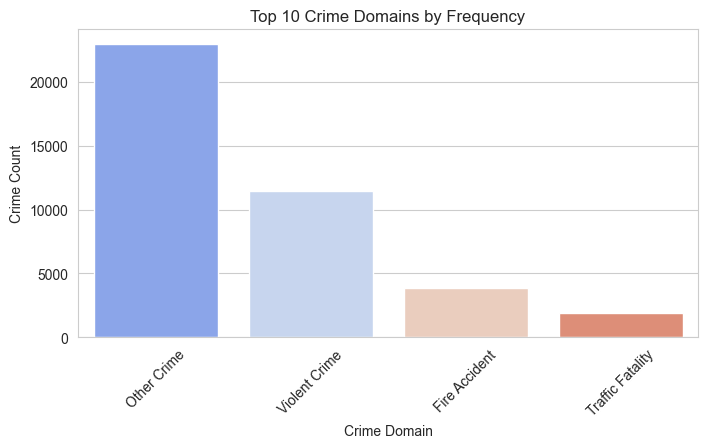

In [22]:
# Plot crime distribution by crime domain (Top 10 most frequent crime types)
top_crime_domains = df["Crime Domain"].value_counts().nlargest(10)

plt.figure(figsize=(8, 4))
sns.barplot(x=top_crime_domains.index, y=top_crime_domains.values, palette="coolwarm")

# Labels and title
plt.xlabel("Crime Domain")
plt.ylabel("Crime Count")
plt.title("Top 10 Crime Domains by Frequency")
plt.xticks(rotation=45)

# Show plot
plt.show()


*Relationship between Crime Description and Weapon Used*

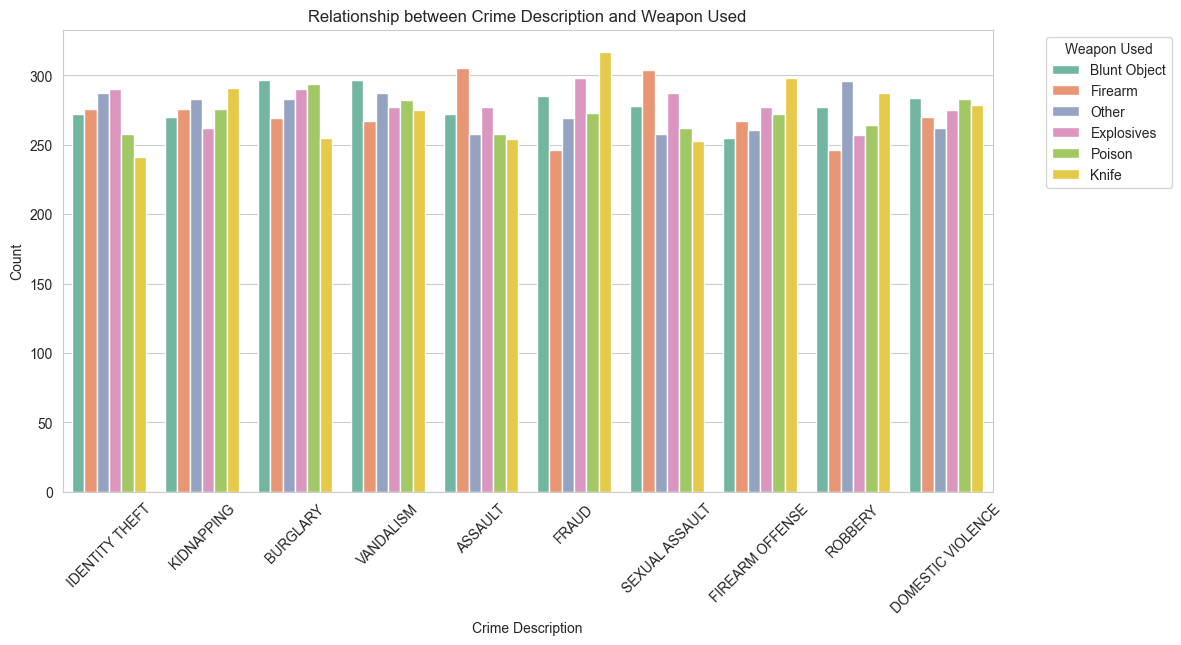

In [23]:
# Plot relationship between Crime Description and Weapon Used (Top 10 crimes)
top_crimes = df["Crime Description"].value_counts().nlargest(10).index
df_filtered = df[df["Crime Description"].isin(top_crimes)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_filtered, x="Crime Description", hue="Weapon Used", palette="Set2")

# Labels and title
plt.xlabel("Crime Description")
plt.ylabel("Count")
plt.title("Relationship between Crime Description and Weapon Used")
plt.xticks(rotation=45)
plt.legend(title="Weapon Used", bbox_to_anchor=(1.05, 1), loc="upper left")

# Show plot
plt.show()


*Correlation between Victim Age and Crime Domain*

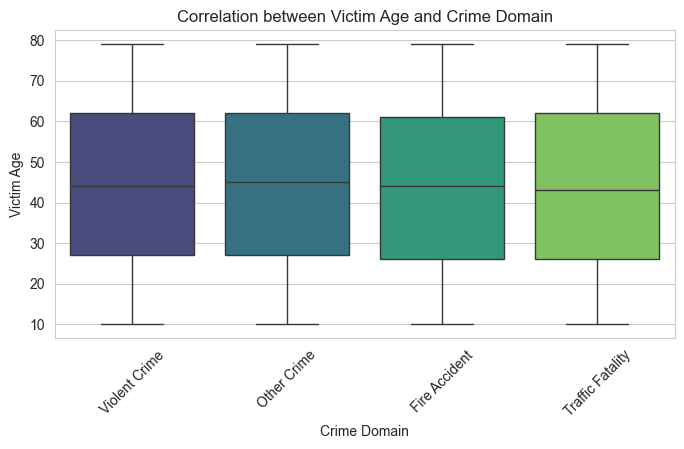

In [26]:
# Plot correlation between Victim Age and Crime Type (Top 10 crime types)
top_crimes = df["Crime Domain"].value_counts().nlargest(10).index
df_filtered = df[df["Crime Domain"].isin(top_crimes)]

plt.figure(figsize=(8,4))
sns.boxplot(data=df_filtered, x="Crime Domain", y="Victim Age", palette="viridis")

# Labels and title
plt.xlabel("Crime Domain")
plt.ylabel("Victim Age")
plt.title("Correlation between Victim Age and Crime Domain")
plt.xticks(rotation=45)

# Show plot
plt.show()


*Gender-Based Crime Trends*

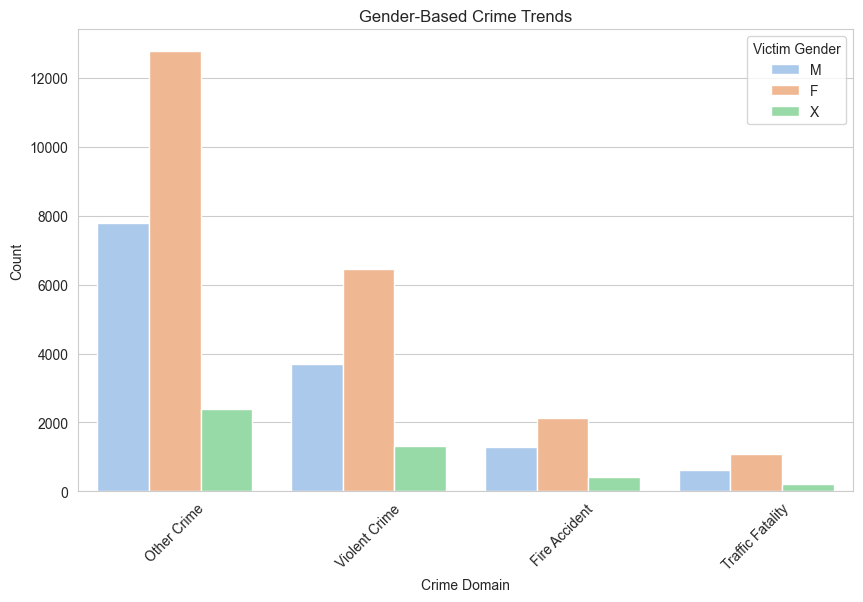

In [28]:
# Plot gender-based crime trends
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Crime Domain", hue="Victim Gender", palette="pastel", order=df["Crime Domain"].value_counts().index[:10])

# Labels and title
plt.xlabel("Crime Domain")
plt.ylabel("Count")
plt.title("Gender-Based Crime Trends")
plt.xticks(rotation=45)
plt.legend(title="Victim Gender")

# Show plot
plt.show()


In [31]:
# Drop the specified columns
columns_to_drop = ['Date Reported','Date of Occurrence','Time of Occurrence','Date Case Closed','Case Closed','Police Deployed']  # Replace with the exact column names or indices
df = df.drop(columns=columns_to_drop, errors='ignore')

*Taking Value Counts*

In [ ]:
df['City'].value_counts()

: 

In [35]:
df['Crime Description'].value_counts()

Crime Description
BURGLARY               1980
VANDALISM              1975
FRAUD                  1965
DOMESTIC VIOLENCE      1932
FIREARM OFFENSE        1931
ROBBERY                1928
KIDNAPPING             1920
IDENTITY THEFT         1918
SEXUAL ASSAULT         1917
ASSAULT                1915
TRAFFIC VIOLATION      1915
PUBLIC INTOXICATION    1912
HOMICIDE               1909
CYBERCRIME             1899
ILLEGAL POSSESSION     1895
ARSON                  1894
DRUG OFFENSE           1890
EXTORTION              1873
COUNTERFEITING         1871
VEHICLE - STOLEN       1862
SHOPLIFTING            1859
Name: count, dtype: int64

In [36]:
df['Victim Gender'].value_counts()

Victim Gender
F    22423
M    13405
X     4332
Name: count, dtype: int64

In [37]:
df['Weapon Used'].value_counts()

Weapon Used
Knife           5835
Explosives      5751
Blunt Object    5737
Poison          5728
Other           5676
Firearm         5643
Name: count, dtype: int64

*label Encoding*

In [38]:
from sklearn.preprocessing import LabelEncoder

# List of categorical columns to encode
categorical_columns = ['City','Crime Description','Victim Gender','Weapon Used']

# Initialize the label encoder
label_encoder = LabelEncoder()

# Apply label encoding to each of the categorical columns
for col in categorical_columns:
    df[col] = label_encoder.fit_transform(df[col])

# Display the first few rows of the updated dataset
df['City'].value_counts()


City
5     5400
17    4415
2     3588
8     2881
13    2518
4     2493
21    2212
1     1817
10    1479
14    1456
12    1112
24    1111
18    1053
0      764
15     761
28     728
25     706
7      704
9      699
20     695
3      690
16     395
23     371
19     366
27     362
26     355
11     355
6      354
22     320
Name: count, dtype: int64

In [39]:
df['Crime Description'].value_counts()

Crime Description
2     1980
19    1975
9     1965
5     1932
8     1931
15    1928
13    1920
11    1918
16    1917
1     1915
18    1915
14    1912
10    1909
4     1899
12    1895
0     1894
6     1890
7     1873
3     1871
20    1862
17    1859
Name: count, dtype: int64

In [40]:
df['Victim Gender'].value_counts()

Victim Gender
0    22423
1    13405
2     4332
Name: count, dtype: int64

In [41]:
df['Weapon Used'].value_counts()

Weapon Used
3    5835
6    5790
1    5751
0    5737
5    5728
4    5676
2    5643
Name: count, dtype: int64

*TargetVariable*

In [42]:
df['Crime Domain'].value_counts()

Crime Domain
Other Crime         22948
Violent Crime       11472
Fire Accident        3825
Traffic Fatality     1915
Name: count, dtype: int64

In [43]:
# Initialize LabelEncoder
label_encoder = LabelEncoder()
# Encoding 'Crime_Category' column 
df['Crime Domain'] = label_encoder.fit_transform(df['Crime Domain'])
df['Crime Domain'].value_counts()

Crime Domain
1    22948
3    11472
0     3825
2     1915
Name: count, dtype: int64

*Data Correlation*

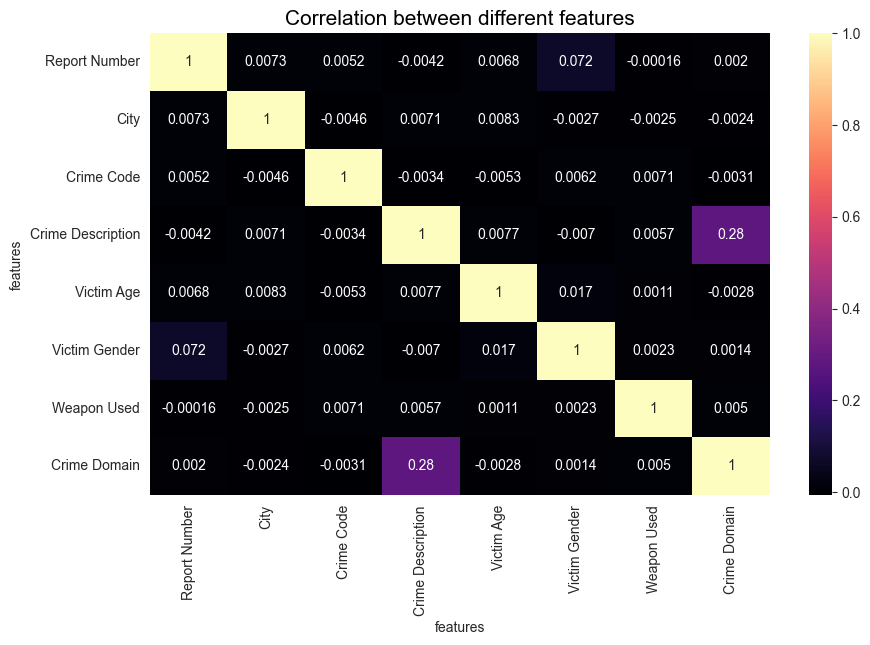

In [44]:

fig, ax = plt.subplots(1, 1, figsize=(10, 6))
sns.heatmap(df.corr(), annot=True,cmap='magma')
ax.set(xlabel='features')
ax.set(ylabel='features')

plt.title('Correlation between different features', fontsize = 15, c='black')
plt.show()

*Saving Cleaned File*

In [45]:
df.to_csv('crime_cleaned_data.csv',index=False)

crime = pd.read_csv('crime_cleaned_data.csv')
crime

,Report Number,City,Crime Code,Crime Description,Victim Age,Victim Gender,Weapon Used,Crime Domain
0,1,1,576,11,16,1,0,3
1,2,4,128,10,37,1,5,1
2,3,15,271,13,48,0,0,1
3,4,21,170,2,49,0,2,1
4,5,21,421,19,30,0,4,1
...,...,...,...,...,...,...,...,...
40155,40156,13,312,3,78,0,2,1
40156,40157,17,300,12,75,0,6,1
40157,40158,12,423,20,68,1,4,3
40158,40159,20,311,16,11,1,0,3


*Splitting of Data*

In [47]:
from sklearn.model_selection import train_test_split

# Assume df is your DataFrame
# Define feature set and target label
X = df.drop(columns=['Crime Domain'])
y = df['Crime Domain']


# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,            # Features
    y,            # Target labels
    test_size=0.3, # Proportion of the dataset to include in the test split
    random_state=11 # Seed for the random number generator
)

# Optionally, print the shapes of the resulting splits
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (28112, 7)
y_train shape:  (28112,)
X_test shape:  (12048, 7)
y_test shape:  (12048,)


*Decision Tree*

In [48]:
from sklearn.tree import DecisionTreeClassifier 
# Initializing
DT = DecisionTreeClassifier()
DT.fit(X_train, y_train)
from sklearn.model_selection import cross_val_score

# y_predict = DT.predict(X_test)
print('*'*20)

# prediction
train_pred=DT.predict(X_train)
test_pred= DT.predict(X_test)
print('*'*20)
# accuracy
print('Train accuracy:' , accuracy_score(y_train,train_pred))
print('Test accuracy:' , accuracy_score(y_test,test_pred))

print('*'*20)
 # cross validation   
score= cross_val_score(DT,X,y,cv=5)
print(score)
print(score.mean())

print('*'*20)
#  prediction Summary by species
print(classification_report(y_test, test_pred))

print('*'*20)
# Accuracy score
DT_SC = accuracy_score(y_train,train_pred)
print(f"{round(DT_SC*100,2)}% Accurate")

print('*'*20)

********************
********************
Train accuracy: 1.0
Test accuracy: 1.0
********************
[1. 1. 1. 1. 1.]
1.0
********************
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1183
           1       1.00      1.00      1.00      6851
           2       1.00      1.00      1.00       536
           3       1.00      1.00      1.00      3478

    accuracy                           1.00     12048
   macro avg       1.00      1.00      1.00     12048
weighted avg       1.00      1.00      1.00     12048

********************
100.0% Accurate
********************


*Adaptive Region Partitioning (ARP)*

In [49]:
from sklearn.ensemble import RandomForestClassifier

# Initiallizing 
rfc=RandomForestClassifier(random_state=42)
rfc.fit(X_train,y_train)
print('*'*20)

# prediction
train_prediction= rfc.predict(X_train)
test_prediction= rfc.predict(X_test)
print('*'*20)

# evaluation
from sklearn.metrics import accuracy_score
print('test accuracy:',accuracy_score(y_test,test_prediction))
print('train accuracy:',accuracy_score(y_train,train_prediction))
print('*'*20)

# # cross validation score
from sklearn.model_selection import cross_val_score
score=cross_val_score(rfc,X,y,cv=5)
print(score.mean())
print('*'*20)

#  prediction 
print(classification_report(y_test, test_prediction))
print('*'*20)

# Accuracy score
RF_SC = accuracy_score(test_prediction,y_test)
print(f"{round(RF_SC*100,2)}% Accurate")

********************
********************
test accuracy: 0.9798306772908366
train accuracy: 1.0
********************
0.6268924302788845
********************
              precision    recall  f1-score   support

           0       1.00      0.85      0.92      1183
           1       0.97      1.00      0.98      6851
           2       1.00      0.99      0.99       536
           3       1.00      0.98      0.99      3478

    accuracy                           0.98     12048
   macro avg       0.99      0.95      0.97     12048
weighted avg       0.98      0.98      0.98     12048

********************
97.98% Accurate


*Logistic Regression*

In [50]:
from sklearn.linear_model import LogisticRegression

# Initializing 
LR = LogisticRegression()
LR.fit(X_train, y_train)


# prediction
train_prediction= LR.predict(X_train)
test_prediction= LR.predict(X_test)
print('*'*20)

# evaluation
from sklearn.metrics import accuracy_score
print('test accuracy:',accuracy_score(y_test,test_prediction))
print('train accuracy:',accuracy_score(y_train,train_prediction))
print('*'*20)

# cross validation score
from sklearn.model_selection import cross_val_score
score=cross_val_score(LR,X,y,cv=5)
print(score.mean())
print('*'*20)

print(classification_report(y_test,test_pred))

print('*'*20)


lr_HSC = accuracy_score(y_test,test_prediction)
print(f"{round(lr_HSC*100,2)}% Accurate")

********************
test accuracy: 0.5686420982735724
train accuracy: 0.5726024473534433
********************
0.571414342629482
********************
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1183
           1       1.00      1.00      1.00      6851
           2       1.00      1.00      1.00       536
           3       1.00      1.00      1.00      3478

    accuracy                           1.00     12048
   macro avg       1.00      1.00      1.00     12048
weighted avg       1.00      1.00      1.00     12048

********************
56.86% Accurate


*AdaBoost*

In [51]:
from sklearn.ensemble import AdaBoostClassifier

# Initializing AdaBoost Classifier
adb_model = AdaBoostClassifier(
    n_estimators=50,        # Number of weak learners (default is 50)
    random_state=11         # Seed for reproducibility
)

# Fitting the model
adb_model.fit(X_train, y_train)

# Predictions
train_prediction = adb_model.predict(X_train)
test_prediction = adb_model.predict(X_test)
print('*' * 20)

# Evaluation
print('Test accuracy:', accuracy_score(y_test, test_prediction))
print('Train accuracy:', accuracy_score(y_train, train_prediction))
print('*' * 20)


# Classification report
print('Classification report:\n', classification_report(y_test, test_prediction))
print('*' * 20)

# AdaBoost model accuracy
adb_HSC = accuracy_score(y_test, test_prediction)
print(f"{round(adb_HSC * 100, 2)}% Accurate")

********************
Test accuracy: 0.7127324037184595
Train accuracy: 0.7131474103585658
********************
Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1183
           1       0.66      1.00      0.80      6851
           2       0.00      0.00      0.00       536
           3       1.00      0.16      0.27      3478

    accuracy                           0.71     12048
   macro avg       0.67      0.54      0.52     12048
weighted avg       0.76      0.71      0.63     12048

********************
71.27% Accurate


*LGBM*

In [52]:
import lightgbm as lgb
from sklearn.model_selection import cross_val_score

# Initializing LGBM Classifier
lgbm_model = lgb.LGBMClassifier(
    n_estimators=100,        # Number of boosting rounds
    random_state=11          # Seed for reproducibility
)

# Fitting the model
lgbm_model.fit(X_train, y_train)

# Predictions
train_prediction = lgbm_model.predict(X_train)
test_prediction = lgbm_model.predict(X_test)
print('*' * 20)

# Evaluation
print('Test accuracy:', accuracy_score(y_test, test_prediction))
print('Train accuracy:', accuracy_score(y_train, train_prediction))
print('*' * 20)

# Cross-validation score
score = cross_val_score(lgbm_model, X, y, cv=5)
print('Cross-validation score mean:', score.mean())
print('*' * 20)

# Classification report
print('Classification report:\n', classification_report(y_test, test_prediction))
print('*' * 20)

# LGBM model accuracy
lgbm_HSC = accuracy_score(y_test, test_prediction)
print(f"{round(lgbm_HSC * 100, 2)}% Accurate")


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002156 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 638
[LightGBM] [Info] Number of data points in the train set: 28112, number of used features: 7
[LightGBM] [Info] Start training from score -2.364660
[LightGBM] [Info] Start training from score -0.557564
[LightGBM] [Info] Start training from score -3.014838
[LightGBM] [Info] Start training from score -1.257505
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive 

*ANN*

In [53]:
from keras.models import Sequential
from keras.layers import Dense

# Define the model
ann = Sequential()
ann.add(Dense(units=64, input_dim=X_train.shape[1], kernel_initializer='uniform', activation='relu'))  # input_dim should be the number of features
ann.add(Dense(units=32, kernel_initializer='uniform', activation='relu'))
ann.add(Dense(units=1, kernel_initializer='uniform', activation='sigmoid'))

# Compile the model
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Fit the model
ann.fit(X_train, y_train, epochs=15, batch_size=32)

from sklearn.metrics import accuracy_score,confusion_matrix

print('test accuracy:', accuracy_score(y_test,test_prediction))
print('train accuracy:', accuracy_score(y_train,train_prediction))
print(confusion_matrix(y_test,test_prediction))


ann_hc = accuracy_score(y_test,test_prediction)
print(f"{round(ann_hc*100,2)}% Accurate")

Epoch 1/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 12s 3ms/step - accuracy: 0.5614 - loss: -1206752.0000
Epoch 2/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5702 - loss: -43366628.0000
Epoch 3/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5727 - loss: -206958288.0000
Epoch 4/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5722 - loss: -545332288.0000
Epoch 5/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5720 - loss: -1082258560.0000
Epoch 6/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5666 - loss: -1790941056.0000
Epoch 7/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5762 - loss: -2707832064.0000
Epoch 8/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5739 - loss: -4007438080.0000
Epoch 9/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5717 - loss: -5464814080.0000
Epoch 10/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5737 - loss: -7119932928.0000
Epoch 11/15
879/879 ━━━━━━━━━━━━━━━━━━━━ 2s 2

*Comparision*

In [54]:
score = [DT_SC,RF_SC,lgbm_HSC,adb_HSC,lr_HSC,ann_hc]
Models = pd.DataFrame({
    'n_neighbors': ["Decision Tree","Adaptive Region Partitioning (ARP)","Lightgbm","AdaBoostClassifier","Logistic Regression","ANN"],
    'Score': score})
Models.sort_values(by='Score', ascending=False)

,n_neighbors,Score
0,Decision Tree,1.000000
2,Lightgbm,1.000000
5,ANN,1.000000
1,Random Forest,0.979831
3,AdaBoostClassifier,0.712732
4,Logistic Regression,0.568642


*Saving Model*

In [55]:
import pickle 

In [56]:
# save the model
model = DT  # Your machine learning model object
file_path = 'DT-cyber.pkl'  # Path to the file where you want to save the model

with open(file_path, 'wb') as file:
    pickle.dump(model, file)

In [57]:
import pickle
# load the model

file_path = 'DT-cyber.pkl'  # Path to the saved model file

with open(file_path, 'rb') as file:
    loaded_model = pickle.load(file)

*User's Prediction*

In [58]:
loaded_model.predict([[1,1,576,11,16,1,0]])

array([3])

In [59]:
loaded_model.predict([[3,15,271,13,48,0,0]])

array([1])

In [60]:
loaded_model.predict([[18,21,342,0,64,0,4]])

array([0])